# Book Review Sentiment: VADER vs. a Transformer

Walkthrough of `src/analyze.py`. Two approaches score each review, and both are checked against the star rating the reviewer gave.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt
import analyze

plt.rcParams['figure.figsize'] = (7, 4)

/Users/jminc/code/python/nlp/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1102 14:29:19.576000 32146 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Load data

Star ratings are mapped to labels (1-2 negative, 3 neutral, 4-5 positive). They act as a ground truth to measure the models against.

In [2]:
df = analyze.load_reviews()
print(len(df), 'reviews')
df[['reviewText', 'rating', 'rating_label']].head()

100 reviews


,reviewText,rating,rating_label
0,Clean and funny. A bit busy with all the diffe...,3,neutral
1,Alex a sexy hot cop and the PhD candidate. Wha...,4,positive
2,Good thing that this is a free story. I read i...,1,negative
3,"Action, action, action! Equipment keeps gettin...",4,positive
4,this was hands down the worse book i have ever...,1,negative


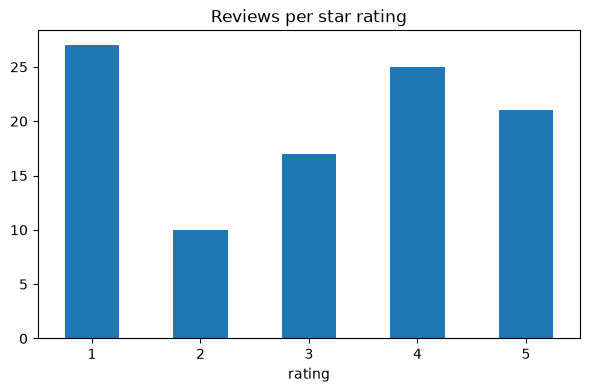

In [3]:
df['rating'].value_counts().sort_index().plot.bar(rot=0, title='Reviews per star rating')
plt.show()

## Rule-based: VADER

VADER scores words from a sentiment lexicon and adjusts for capitalisation, punctuation and simple negation. It is fast and needs no training. It runs on the **raw** text, because lowercasing and stripping punctuation would throw away signals it uses.

In [4]:
df = analyze.add_vader(df)
df[['reviewText', 'vader_score', 'vader_label']].head()

,reviewText,vader_score,vader_label
0,Clean and funny. A bit busy with all the diffe...,0.7684,positive
1,Alex a sexy hot cop and the PhD candidate. Wha...,0.9325,positive
2,Good thing that this is a free story. I read i...,0.6740,positive
3,"Action, action, action! Equipment keeps gettin...",0.6948,positive
4,this was hands down the worse book i have ever...,-0.4767,negative


## Pre-trained transformer

A DistilBERT model fine-tuned on movie-review sentiment (SST-2). It reads whole sentences in context, but only answers positive or negative.

In [5]:
df = analyze.add_transformer(df)
df[['reviewText', 'transformer_label', 'transformer_score']].head()

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 9507.37it/s]

,reviewText,transformer_label,transformer_score
0,Clean and funny. A bit busy with all the diffe...,positive,0.999620
1,Alex a sexy hot cop and the PhD candidate. Wha...,positive,0.999873
2,Good thing that this is a free story. I read i...,negative,0.999712
3,"Action, action, action! Equipment keeps gettin...",positive,0.988936
4,this was hands down the worse book i have ever...,negative,0.999435


## Comparing label distributions

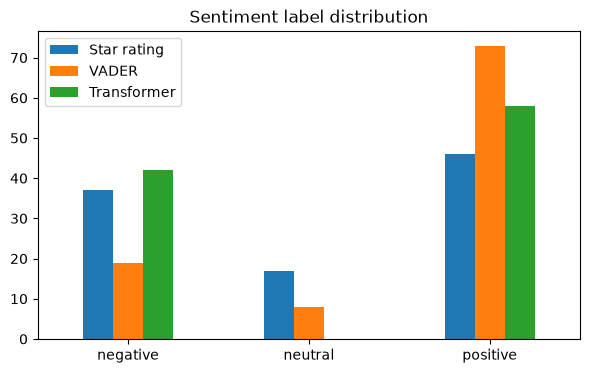

In [6]:
pd.DataFrame({
    'Star rating': df['rating_label'].value_counts(),
    'VADER': df['vader_label'].value_counts(),
    'Transformer': df['transformer_label'].value_counts(),
}).reindex(analyze.LABELS).fillna(0).astype(int).plot.bar(rot=0, title='Sentiment label distribution')
plt.show()

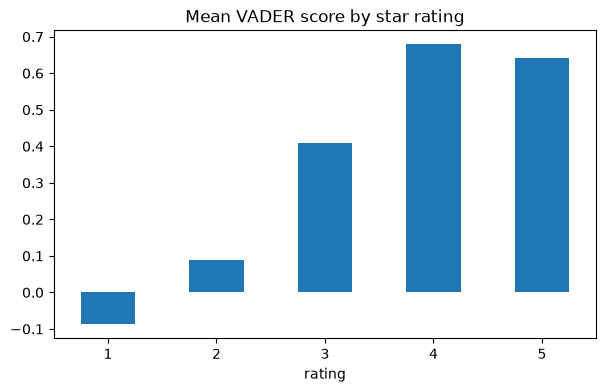

In [7]:
df.groupby('rating')['vader_score'].mean().plot.bar(rot=0, title='Mean VADER score by star rating')
plt.show()

## Accuracy against star ratings

3-star reviews are left out here because they have no clear polarity.

In [8]:
analyze.evaluate(df, 'vader_label', 'VADER')


VADER vs. star ratings (1-2 = negative, 4-5 = positive, n=83)
              precision    recall  f1-score   support

    negative       0.94      0.43      0.59        37
    positive       0.74      0.98      0.84        46

   micro avg       0.78      0.73      0.76        83
   macro avg       0.84      0.71      0.72        83
weighted avg       0.83      0.73      0.73        83



In [9]:
analyze.evaluate(df, 'transformer_label', 'Transformer')


Transformer vs. star ratings (1-2 = negative, 4-5 = positive, n=83)
              precision    recall  f1-score   support

    negative       1.00      0.95      0.97        37
    positive       0.96      1.00      0.98        46

    accuracy                           0.98        83
   macro avg       0.98      0.97      0.98        83
weighted avg       0.98      0.98      0.98        83



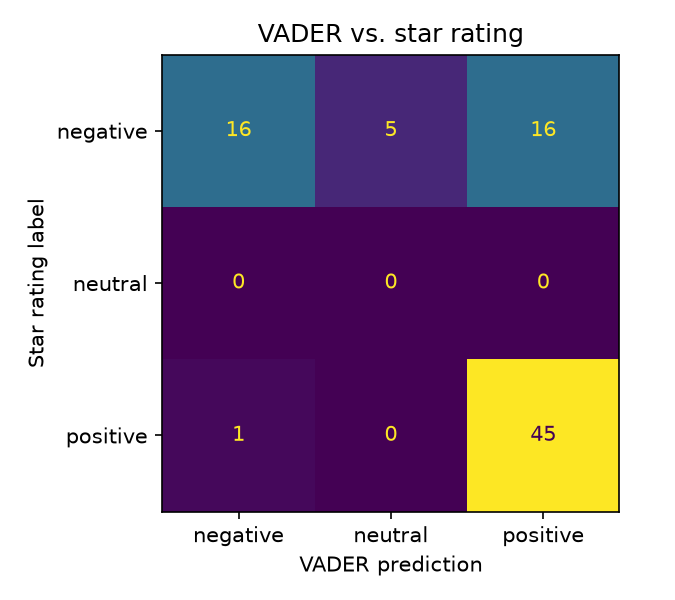

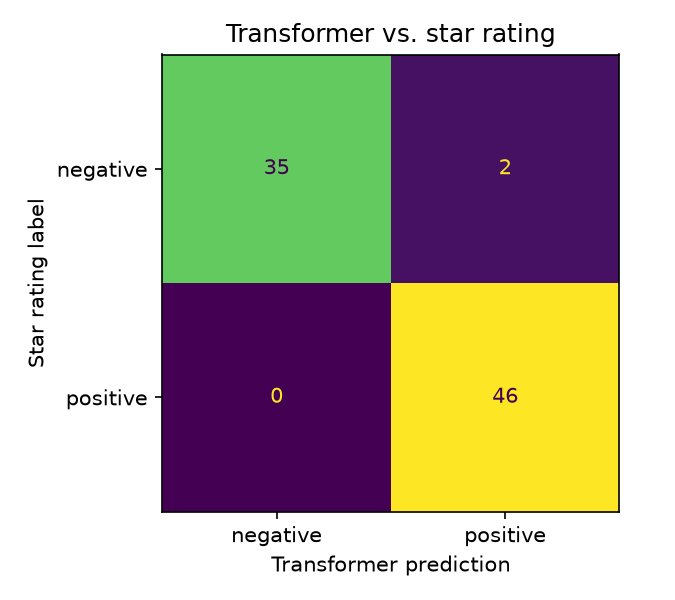

In [10]:
from IPython.display import Image, display
for n in ['vader', 'transformer']:
    display(Image(f'../outputs/confusion_{n}.png', width=350))

## Where VADER goes wrong

Negative reviews that VADER scored as positive. Phrases like "not worth the time" contain positive words ("worth") and VADER's negation handling doesn't always catch them.

In [11]:
pd.set_option('display.max_colwidth', 120)
df[(df['rating_label'] == 'negative') & (df['vader_label'] == 'positive')][['reviewText', 'rating', 'vader_score', 'transformer_label']].head(8)

,reviewText,rating,vader_score,transformer_label
2,Good thing that this is a free story. I read it a few years ago and it is not worth the time.,1,0.6740,negative
10,let down. Did not think it was worth the money spent at all. Nothing in it seemed of real value.,1,0.5106,negative
12,This was to short. I will not be telling my friends bout it. I did not like the topic of the story.,1,0.2477,negative
19,"I read books to make me happy, laugh and generally make my day - I don't like books that make me sad",1,0.4749,positive
22,And good tittle but not much else here. I bought more but got only a good title. No thanks for that.,1,0.4001,negative
47,i was not expecting what this book had to offer. This book was just not for me. Was well written,1,0.2732,negative
50,"I do not like this one please remove it from my library. Thanks, cj",1,0.4749,negative
59,I am not real sure about this book just seemed weird from the get go glad it was .99 cents,1,0.0869,negative
